In [1]:
from __future__ import division # must be first
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib import rc
import matplotlib.gridspec as gridspec
from matplotlib.figure import Figure
import matplotlib
from matplotlib import rc
from scipy.io import loadmat
from scipy.integrate import odeint
from scipy.integrate import quad
from mpmath import gammainc
import numbers
import pickle
from scipy.stats import dirichlet
from tqdm import tqdm
import matplotlib.patches as mpatches
from scipy.spatial.distance import jensenshannon
import pandas as pd
import os
from matplotlib.path import Path
import matplotlib.ticker as ticker
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl


def is_real_number(num):
  return isinstance(num, numbers.Number)


from scipy.special import gamma, gammaincc, expn

from scipy.optimize import curve_fit
rc('font', **{'family': 'sans-serif', 'sans-serif': ['Arial']})
plt.style.use('Leighton_Style_Colors2')

mpl.rcParams.update({
    "text.usetex": False,          # turn off LaTeX
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],  # try Arial first, then fallbacks
})

mpl.rcParams["xtick.labelsize"] = 8
mpl.rcParams["ytick.labelsize"] = 8


### Plotting Utilities

In [3]:
##### Plotting Helper Functions for Fig b:


def make_snowflake_path(
    n_arms=6,            # number of main arms (typical snowflake uses 6)
    R=1.0,               # main arm length (relative)
    branch_at=0.55,      # where along the arm the side branches start (0..1)
    branch_len=0.35,     # length of side branches (relative to R)
    branch_angle_deg=30, # angle of side branches from the arm direction
    hub=0.12             # radius of a small central hub (0 to disable)
):
    verts, codes = [], []
    for i in range(n_arms):
        theta = i * 2 * np.pi / n_arms

        # main arm
        x0, y0 = 0.0, 0.0
        x1, y1 = R * np.cos(theta), R * np.sin(theta)
        verts += [(x0, y0), (x1, y1)]
        codes += [Path.MOVETO, Path.LINETO]

        # side branches on each arm (± branch_angle)
        xb, yb = branch_at * R * np.cos(theta), branch_at * R * np.sin(theta)
        for sgn in (+1, -1):
            phi = theta + sgn * np.deg2rad(branch_angle_deg)
            x2, y2 = xb + branch_len * np.cos(phi), yb + branch_len * np.sin(phi)
            verts += [(xb, yb), (x2, y2)]
            codes += [Path.MOVETO, Path.LINETO]

    # optional small hub polygon to make the center look finished
    if hub > 0:
        for i in range(n_arms):
            ang = i * 2 * np.pi / n_arms
            p = (hub * np.cos(ang), hub * np.sin(ang))
            if i == 0:
                verts.append(p); codes.append(Path.MOVETO)
            else:
                verts.append(p); codes.append(Path.LINETO)
        verts.append((0.0, 0.0)); codes.append(Path.CLOSEPOLY)

    # normalize to unit radius so marker sizing behaves as expected
    arr = np.asarray(verts, dtype=float)
    m = np.max(np.hypot(arr[:,0], arr[:,1]))
    if m > 0:
        arr /= m

    return Path(arr, codes)

snowflake_path = make_snowflake_path()

from matplotlib.patches import FancyArrowPatch

def add_parallel_arrow(x, y, idx=None, span=1, offset=0.02, frac=0.6, ax=None, **kw):
    """
    Draw an arrow parallel to the polyline (x,y), shifted to the right.
    idx:   starting vertex index to set the direction
    span:  use segment [idx, idx+span] to define orientation
    offset: perpendicular shift (in data units)
    frac:  fraction of the chosen segment length to draw as arrow
    """
    if ax is None: ax = plt.gca()
    x = np.asarray(x); y = np.asarray(y)
    if idx is None:
        idx = max(0, len(x)//2 - 1)
    j = min(len(x)-1, idx+span)

    # direction vector along the polyline
    vx, vy = x[j] - x[idx], y[j] - y[idx]
    L = np.hypot(vx, vy)
    if L == 0: return
    ux, uy = vx / L, vy / L

    # normal vector; choose sign so the shift increases x (i.e., moves "right")
    nx, ny = -uy, ux
    if (x[idx] + offset*nx) < x[idx]:
        nx, ny = -nx, -ny

    # start & end of the arrow, shifted to the right of the line
    start = (x[idx] + offset*nx, y[idx] + offset*ny)
    end   = (start[0] + frac*L*ux, start[1] + frac*L*uy)

    arr = FancyArrowPatch(start, end, arrowstyle='-|>',
                          mutation_scale=12, lw=1, color='black',
                          alpha=1, clip_on=False, **kw)
    ax.add_patch(arr)



In [4]:
def format_axes(ax, minor_ticks_x=2, minor_ticks_y=2,
                stroke_in=0.01):
    lw = stroke_in * 72  # convert to points
    ax.minorticks_on()
    if ax.get_xscale() == 'log':
        ax.xaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_x))
    if ax.get_yscale() == 'log':
        ax.yaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_y))
    # spines
    for spine in ax.spines.values():
        spine.set_linewidth(lw)
        spine.set_color('black')
    # tick parameters
    ax.tick_params(which='major', width=lw, length=4.5, direction='in',
                   top=True, bottom=True, left=True, right=True)
    ax.tick_params(which='minor', width=lw * 0.75, length=2.25, direction='in',
                   top=True, bottom=True, left=True, right=True)
    return ax


In [5]:
import matplotlib.ticker as ticker
import matplotlib

def format_axes_histogram(ax, minor_ticks_x=2, minor_ticks_y=2,
                          stroke_in=0.01):
    lw = stroke_in * 72  # convert to points

    # 1) Start with minor ticks OFF everywhere
    ax.minorticks_off()

    # 2) Turn ON minor ticks only for y-axis
    if ax.get_yscale() == 'log':
        ax.yaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_y))
    # (x-axis keeps its default NullLocator -> no minor ticks on x)

    # 3) Spines
    for spine in ax.spines.values():
        spine.set_linewidth(lw)
        spine.set_color('black')

    # 4) Major ticks: we’ll allow bottom, left, right here
    ax.tick_params(which='major', width=lw, length=4.5, direction='in',
                   top=True, bottom=True, left=True, right=True)

    # 5) Minor ticks: these settings apply to y (since x has no minor locs)
    ax.tick_params(which='minor', width=lw * 0.75, length=2.25, direction='in',
                   top=True, bottom=True, left=True, right=True)

    # 6) Make sure x-axis has NO minor tick labels (not really needed,
    #     but safe if you ever add a minor locator later)
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    #ax.xaxis.set_major_formatter(matplotlib.ticker.NullFormatter())
    
    # 7) Turn OFF all top ticks (major + minor) on the x-axis
    ax.tick_params(axis='x', which='both',
               top=False,      # no tick marks at top
               bottom=False,   # no tick marks at bottom
               labelbottom=True)  # but keep the labels at the bottom

    # Optional: if you also want no top border line:
    # ax.spines['top'].set_visible(False)

    return ax


### Other Useful Functions:

In [7]:
import numpy as np

def dirichlet_from_mean_ci(mean, low, high):
    """
    Approximate Dirichlet parameters from mean and 95% CI for each component.
    mean, low, high are 1D arrays of same length.
    """
    mean = np.asarray(mean, dtype=float)
    low  = np.asarray(low,  dtype=float)
    high = np.asarray(high, dtype=float)

    # 95% CI ~ mean ± 1.96 * sigma  =>  sigma ≈ (high - low)/(2*1.96)
    sigma = (high - low) / (2 * 1.96)
    var   = sigma**2

    eps = 1e-12
    var  = np.maximum(var, eps)
    mean = np.clip(mean, eps, 1 - eps)

    # From Var = mean(1-mean)/(alpha0 + 1)  =>  alpha0 ≈ mean(1-mean)/var - 1
    alpha0_est = mean * (1 - mean) / var - 1.0

    # Some components may give crazy values; keep the sensible ones
    mask = np.isfinite(alpha0_est) & (alpha0_est > 0)
    if not np.any(mask):
        raise ValueError("Could not infer a positive alpha0 from the CIs.")

    alpha0 = np.median(alpha0_est[mask])     # one shared concentration
    alpha  = mean * alpha0                   # component-wise alphas

    return alpha

def sample_cooled_distributions(mean, low, high, n_samples=1000, random_state=None):
    rng = np.random.default_rng(random_state)
    alpha = dirichlet_from_mean_ci(mean, low, high)
    samples = rng.dirichlet(alpha, size=n_samples)   # shape (n_samples, n_states)
    return samples

In [8]:
import numpy as np

def dirichlet_from_mean_ci_50(mean, low, high):
    """
    Approximate Dirichlet parameters from mean and 50% CI for each component.
    mean, low, high are 1D arrays of same length.
    """
    mean = np.asarray(mean, dtype=float)
    low  = np.asarray(low,  dtype=float)
    high = np.asarray(high, dtype=float)

    # 50% CI ~ mean ± z * sigma, with z = 0.67448975
    z_50 = 0.67448975
    sigma = (high - low) / (2 * z_50)
    var   = sigma**2

    eps = 1e-12
    var  = np.maximum(var, eps)
    mean = np.clip(mean, eps, 1 - eps)

    # From Var = mean(1-mean)/(alpha0 + 1)  =>  alpha0 ≈ mean(1-mean)/var - 1
    alpha0_est = mean * (1 - mean) / var - 1.0

    mask = np.isfinite(alpha0_est) & (alpha0_est > 0)
    if not np.any(mask):
        raise ValueError("Could not infer a positive alpha0 from the CIs.")

    alpha0 = np.median(alpha0_est[mask])     # one shared concentration
    alpha  = mean * alpha0                   # component-wise alphas

    return alpha

def sample_cooled_distributions_ci50(mean, low, high, n_samples=1000, random_state=None):
    rng = np.random.default_rng(random_state)
    alpha = dirichlet_from_mean_ci_50(mean, low, high)
    samples = rng.dirichlet(alpha, size=n_samples)
    return samples


In [9]:
def compute_EP_UB(pi_h,s,p_tau,Th,Tc):

    E0 = np.sum(pi_h * (-np.log(pi_h) + s))
    S0 = np.sum(pi_h * (s - np.log(pi_h)))
    
    Etau = np.sum(p_tau * (-np.log(pi_h) + s))
    Stau = np.sum(p_tau * (s - np.log(p_tau)))
    
    #Energy Difference (units of kBT):
    Delta_E = Etau - E0

    #Entropy Difference:
    Delta_S = Stau - S0

    #Entropy Production Upper Bound:
    Sigma_UB = Delta_S - Th/Tc * Delta_E

    return Sigma_UB

def compute_EP_aux(pi_h,s,p_tau,Th,Tc):
    pi_c_temp = (pi_h**(Th/Tc) * np.exp((1-Th/Tc)*s))/np.sum(pi_h**(Th/Tc) * np.exp((1-Th/Tc)*s))
    
    Einfty = np.sum(pi_c_temp * (-np.log(pi_h) + s))
    Sinfty = np.sum(pi_c_temp * (s - np.log(pi_c_temp)))

    Etau = np.sum(p_tau * (-np.log(pi_h) + s))
    Stau = np.sum(p_tau * (s - np.log(p_tau)))

    return (-Einfty + Etau)*Th/Tc + Sinfty - Stau
    
def compute_Delta_E(pi_h,s,p_tau,Th,Tc):
    E0 = np.sum(pi_h * (-np.log(pi_h) + s))
    Etau = np.sum(p_tau * (-np.log(pi_h) + s))
    return Etau-E0

def compute_Delta_S(pi_h,s,p_tau,Th,Tc):
    S0 = np.sum(pi_h * (s - np.log(pi_h)))
    Stau = np.sum(p_tau * (s - np.log(p_tau)))
    return Stau - S0

def compute_thermodynamics(pi_temp,s_temp, tau_list, dist_list, Th=277, Tc=230):
    Delta_entropy_list = np.zeros(len(tau_list))
    Delta_energy_list = np.zeros(len(tau_list))
    EP_UB_list = np.zeros(len(tau_list))
    EP_aux_list = np.zeros(len(tau_list))
    
    pi_h = pi_temp
    for k in range(len(tau_list)):

        p_tau_samples = sample_cooled_distributions(dist_list[k], dist_low_list[k], dist_high_list[k], n_samples=1000, random_state=0)
        
        for i in range(1000):
            p_tau = p_tau_samples[i]
            Delta_energy_list[k] += compute_Delta_E(pi_h,s_temp,p_tau,Th,Tc)
            
            Delta_entropy_list[k] += compute_Delta_S(pi_h,s_temp,p_tau,Th,Tc)
        
            EP_UB_list[k] += compute_EP_UB(pi_h,s_temp,p_tau,Th,Tc)
            EP_aux_list[k] += compute_EP_aux(pi_h,s_temp,p_tau,Th,Tc)

    return Delta_energy_list/1000,Delta_entropy_list/1000,EP_UB_list/1000,EP_aux_list/1000



### Data Reading:

In [11]:
dataframe = pd.read_csv('cooling_pairs_summary_k50_t250_lag_400.csv')

states = np.array(dataframe['state'])

state_number = max(states) + 1


# Cooled trajectories over all original states
cooled_6e9_full = dataframe['mean'].to_numpy()[0:state_number].astype(float)
cooled_2e9_full = dataframe['mean'].to_numpy()[state_number:2*state_number].astype(float)
cooled_6e8_full = dataframe['mean'].to_numpy()[2*state_number:3*state_number].astype(float)
cooled_2e8_full = dataframe['mean'].to_numpy()[3*state_number:4*state_number].astype(float)
cooled_6e7_full = dataframe['mean'].to_numpy()[4*state_number:5*state_number].astype(float)
cooled_2e7_full = dataframe['mean'].to_numpy()[5*state_number:6*state_number].astype(float)
cooled_6e6_full = dataframe['mean'].to_numpy()[6*state_number:7*state_number].astype(float)

cooled_6e9_low_full = dataframe['ci_lower_95'].to_numpy()[0:1*state_number].astype(float)
cooled_2e9_low_full = dataframe['ci_lower_95'].to_numpy()[1*state_number:2*state_number].astype(float)
cooled_6e8_low_full = dataframe['ci_lower_95'].to_numpy()[2*state_number:3*state_number].astype(float)
cooled_2e8_low_full = dataframe['ci_lower_95'].to_numpy()[3*state_number:4*state_number].astype(float)
cooled_6e7_low_full = dataframe['ci_lower_95'].to_numpy()[4*state_number:5*state_number].astype(float)
cooled_2e7_low_full = dataframe['ci_lower_95'].to_numpy()[5*state_number:6*state_number].astype(float)
cooled_6e6_low_full = dataframe['ci_lower_95'].to_numpy()[6*state_number:7*state_number].astype(float)

cooled_6e9_high_full = dataframe['ci_upper_95'].to_numpy()[0*state_number:1*state_number].astype(float)
cooled_2e9_high_full = dataframe['ci_upper_95'].to_numpy()[1*state_number:2*state_number].astype(float)
cooled_6e8_high_full = dataframe['ci_upper_95'].to_numpy()[2*state_number:3*state_number].astype(float)
cooled_2e8_high_full = dataframe['ci_upper_95'].to_numpy()[3*state_number:4*state_number].astype(float)
cooled_6e7_high_full = dataframe['ci_upper_95'].to_numpy()[4*state_number:5*state_number].astype(float)
cooled_2e7_high_full = dataframe['ci_upper_95'].to_numpy()[5*state_number:6*state_number].astype(float)
cooled_6e6_high_full = dataframe['ci_upper_95'].to_numpy()[6*state_number:7*state_number].astype(float)

eqm_data_full = dataframe['mean'].to_numpy()[7*state_number:8*state_number].astype(float)
hot_eqm_low_full = dataframe['ci_lower_95'].to_numpy()[7*state_number:8*state_number].astype(float)
hot_eqm_high_full = dataframe['ci_upper_95'].to_numpy()[7*state_number:8*state_number].astype(float)
cold_eqm_full = dataframe['mean'].to_numpy()[8*state_number:9*state_number].astype(float)

tau_list = np.array([8,18,80,180,800,1800,8000])
rate_list = np.array([6.4e9,2.7e9,6.4e8,2.7e8,6.4e7,2.7e7,6.4e6])

HOT_EQM_THRESHOLD = 0.01
original_state_numbers = np.arange(state_number, dtype=int)
hot_state_mask_full = eqm_data_full > HOT_EQM_THRESHOLD
hot_state_original_numbers = original_state_numbers[hot_state_mask_full]
other_state_original_numbers = original_state_numbers[~hot_state_mask_full]
if hot_state_original_numbers.size == 0:
    raise ValueError("No equilibrium-hot states found above p > 0.01.")

# Panel A uses the two most probable original equilibrium states.
top_two_original_indices = np.argsort(eqm_data_full)[::-1][:2]
i1_original = int(top_two_original_indices[0])
i2_original = int(top_two_original_indices[1])

# Defaults are full-state arrays; cell 13 may replace these with reduced arrays
# if feasible_p.csv contains the hot+other state space.
cooled_6e9 = cooled_6e9_full.copy()
cooled_2e9 = cooled_2e9_full.copy()
cooled_6e8 = cooled_6e8_full.copy()
cooled_2e8 = cooled_2e8_full.copy()
cooled_6e7 = cooled_6e7_full.copy()
cooled_2e7 = cooled_2e7_full.copy()
cooled_6e6 = cooled_6e6_full.copy()

cooled_6e9_low = cooled_6e9_low_full.copy()
cooled_2e9_low = cooled_2e9_low_full.copy()
cooled_6e8_low = cooled_6e8_low_full.copy()
cooled_2e8_low = cooled_2e8_low_full.copy()
cooled_6e7_low = cooled_6e7_low_full.copy()
cooled_2e7_low = cooled_2e7_low_full.copy()
cooled_6e6_low = cooled_6e6_low_full.copy()

cooled_6e9_high = cooled_6e9_high_full.copy()
cooled_2e9_high = cooled_2e9_high_full.copy()
cooled_6e8_high = cooled_6e8_high_full.copy()
cooled_2e8_high = cooled_2e8_high_full.copy()
cooled_6e7_high = cooled_6e7_high_full.copy()
cooled_2e7_high = cooled_2e7_high_full.copy()
cooled_6e6_high = cooled_6e6_high_full.copy()

eqm_data = eqm_data_full.copy()
hot_eqm_low = hot_eqm_low_full.copy()
hot_eqm_high = hot_eqm_high_full.copy()
cold_eqm = cold_eqm_full.copy()

dist_list = [cooled_6e9,cooled_2e9,cooled_6e8,cooled_2e8,cooled_6e7,cooled_2e7,cooled_6e6]
dist_low_list = [cooled_6e9_low,cooled_2e9_low,cooled_6e8_low,cooled_2e8_low,cooled_6e7_low,cooled_2e7_low,cooled_6e6_low]
dist_high_list = [cooled_6e9_high,cooled_2e9_high,cooled_6e8_high,cooled_2e8_high,cooled_6e7_high,cooled_2e7_high,cooled_6e6_high]



In [12]:

# ------------------------------------------------------------
# 1. Load feasible distributions
# ------------------------------------------------------------
distributions = np.loadtxt('feasible_p.csv')  # shape (N, K)
s_vals = np.loadtxt('feasible_s.csv')
if distributions.ndim == 1:
    distributions = distributions[None, :]
if s_vals.ndim == 0:
    s_vals = np.array([s_vals])
N, K = distributions.shape


# ------------------------------------------------------------
# 1b. Align plotted state-space with feasible_p.csv dimension
#     Supports either full-state (K=state_number) or reduced
#     hot+other state-space (K=n_hot+1).
# ------------------------------------------------------------
def collapse_hot_other(vec, hot_mask, normalize=True):
    vec = np.asarray(vec, dtype=float)
    hot_vals = vec[hot_mask]
    other_val = vec[~hot_mask].sum()
    collapsed = np.concatenate([hot_vals, [other_val]])
    if normalize:
        total = collapsed.sum()
        if total <= 0:
            raise ValueError("Collapsed distribution has non-positive mass.")
        collapsed = collapsed / total
    return collapsed

n_hot = int(hot_state_mask_full.sum())
expected_reduced_dim = n_hot + 1
using_reduced_state_space = False

if K == state_number:
    panel_b_mask = eqm_data > HOT_EQM_THRESHOLD
    panel_b_original_indices = original_state_numbers[panel_b_mask]
    i1 = i1_original
    i2 = i2_original
elif K == expected_reduced_dim:
    using_reduced_state_space = True

    cooled_6e9 = collapse_hot_other(cooled_6e9_full, hot_state_mask_full)
    cooled_2e9 = collapse_hot_other(cooled_2e9_full, hot_state_mask_full)
    cooled_6e8 = collapse_hot_other(cooled_6e8_full, hot_state_mask_full)
    cooled_2e8 = collapse_hot_other(cooled_2e8_full, hot_state_mask_full)
    cooled_6e7 = collapse_hot_other(cooled_6e7_full, hot_state_mask_full)
    cooled_2e7 = collapse_hot_other(cooled_2e7_full, hot_state_mask_full)
    cooled_6e6 = collapse_hot_other(cooled_6e6_full, hot_state_mask_full)

    cooled_6e9_low = collapse_hot_other(cooled_6e9_low_full, hot_state_mask_full, normalize=False)
    cooled_2e9_low = collapse_hot_other(cooled_2e9_low_full, hot_state_mask_full, normalize=False)
    cooled_6e8_low = collapse_hot_other(cooled_6e8_low_full, hot_state_mask_full, normalize=False)
    cooled_2e8_low = collapse_hot_other(cooled_2e8_low_full, hot_state_mask_full, normalize=False)
    cooled_6e7_low = collapse_hot_other(cooled_6e7_low_full, hot_state_mask_full, normalize=False)
    cooled_2e7_low = collapse_hot_other(cooled_2e7_low_full, hot_state_mask_full, normalize=False)
    cooled_6e6_low = collapse_hot_other(cooled_6e6_low_full, hot_state_mask_full, normalize=False)

    cooled_6e9_high = collapse_hot_other(cooled_6e9_high_full, hot_state_mask_full, normalize=False)
    cooled_2e9_high = collapse_hot_other(cooled_2e9_high_full, hot_state_mask_full, normalize=False)
    cooled_6e8_high = collapse_hot_other(cooled_6e8_high_full, hot_state_mask_full, normalize=False)
    cooled_2e8_high = collapse_hot_other(cooled_2e8_high_full, hot_state_mask_full, normalize=False)
    cooled_6e7_high = collapse_hot_other(cooled_6e7_high_full, hot_state_mask_full, normalize=False)
    cooled_2e7_high = collapse_hot_other(cooled_2e7_high_full, hot_state_mask_full, normalize=False)
    cooled_6e6_high = collapse_hot_other(cooled_6e6_high_full, hot_state_mask_full, normalize=False)

    eqm_data = collapse_hot_other(eqm_data_full, hot_state_mask_full)
    hot_eqm_low = collapse_hot_other(hot_eqm_low_full, hot_state_mask_full, normalize=False)
    hot_eqm_high = collapse_hot_other(hot_eqm_high_full, hot_state_mask_full, normalize=False)
    cold_eqm = collapse_hot_other(cold_eqm_full, hot_state_mask_full)

    dist_list = [cooled_6e9,cooled_2e9,cooled_6e8,cooled_2e8,cooled_6e7,cooled_2e7,cooled_6e6]
    dist_low_list = [cooled_6e9_low,cooled_2e9_low,cooled_6e8_low,cooled_2e8_low,cooled_6e7_low,cooled_2e7_low,cooled_6e6_low]
    dist_high_list = [cooled_6e9_high,cooled_2e9_high,cooled_6e8_high,cooled_2e8_high,cooled_6e7_high,cooled_2e7_high,cooled_6e6_high]

    i1_hits = np.where(hot_state_original_numbers == i1_original)[0]
    i2_hits = np.where(hot_state_original_numbers == i2_original)[0]
    if i1_hits.size == 0 or i2_hits.size == 0:
        raise ValueError("Top two equilibrium states are not present in reduced hot-state space.")
    i1 = int(i1_hits[0])
    i2 = int(i2_hits[0])

    panel_b_mask = np.zeros(K, dtype=bool)
    panel_b_mask[:n_hot] = True  # only states with original eqm p > 0.01
    panel_b_original_indices = hot_state_original_numbers.copy()
else:
    raise ValueError(
        f"Unexpected feasible_p dimension K={K}. Expected full ({state_number}) or reduced ({expected_reduced_dim})."
    )

print(f"Loaded feasible state-space with K={K} (reduced={using_reduced_state_space}).")
print(f"Panel A states (x,y) original indices: ({i1_original}, {i2_original})")



Loaded feasible state-space with K=10 (reduced=True).
Panel A states (x,y) original indices: (23, 10)


### Prepare the Figure S15 state space using Figure 6 inference settings


In [14]:
q1 = cooled_6e9
q2 = cooled_2e9
p0 = 0.5 * (q1 + q2)
dists = np.linalg.norm((distributions - p0) / p0, axis=1)
p_hat = distributions[np.argmin(dists)]

k_near = min(140, N)
idx_near = np.argsort(dists)[:k_near]
near = distributions[idx_near]
near_s = s_vals[idx_near]

p_med = np.median(near, axis=0)
p_lo = np.percentile(near, 16, axis=0)
p_hi = np.percentile(near, 84, axis=0)
p_err_low = p_med - p_lo
p_err_high = p_hi - p_med

p_med = p_med / np.sum(p_med)

if using_reduced_state_space:
    hot_plot_indices = np.arange(n_hot)
else:
    hot_plot_indices = np.where(panel_b_mask)[0]

hot_sort_order = np.argsort(eqm_data[hot_plot_indices])[::-1]
hot_plot_indices = hot_plot_indices[hot_sort_order]
plot_state_labels = np.asarray(panel_b_original_indices)[hot_sort_order].tolist()
n_plot_states = len(plot_state_labels)


def select_plot_states(values):
    return np.asarray(values)[hot_plot_indices]


distributions = distributions[:, hot_plot_indices]
s_vals = s_vals[:, hot_plot_indices]
near = near[:, hot_plot_indices]
near_s = near_s[:, hot_plot_indices]
p_med = select_plot_states(p_med)
p_err_low = select_plot_states(p_err_low)
p_err_high = select_plot_states(p_err_high)

cooled_6e9 = select_plot_states(cooled_6e9)
cooled_2e9 = select_plot_states(cooled_2e9)
cooled_6e8 = select_plot_states(cooled_6e8)
cooled_2e8 = select_plot_states(cooled_2e8)
cooled_6e7 = select_plot_states(cooled_6e7)
cooled_2e7 = select_plot_states(cooled_2e7)
cooled_6e6 = select_plot_states(cooled_6e6)

cooled_6e9_low = select_plot_states(cooled_6e9_low)
cooled_2e9_low = select_plot_states(cooled_2e9_low)
cooled_6e8_low = select_plot_states(cooled_6e8_low)
cooled_2e8_low = select_plot_states(cooled_2e8_low)
cooled_6e7_low = select_plot_states(cooled_6e7_low)
cooled_2e7_low = select_plot_states(cooled_2e7_low)
cooled_6e6_low = select_plot_states(cooled_6e6_low)

cooled_6e9_high = select_plot_states(cooled_6e9_high)
cooled_2e9_high = select_plot_states(cooled_2e9_high)
cooled_6e8_high = select_plot_states(cooled_6e8_high)
cooled_2e8_high = select_plot_states(cooled_2e8_high)
cooled_6e7_high = select_plot_states(cooled_6e7_high)
cooled_2e7_high = select_plot_states(cooled_2e7_high)
cooled_6e6_high = select_plot_states(cooled_6e6_high)

eqm_data = select_plot_states(eqm_data)
hot_eqm_low = select_plot_states(hot_eqm_low)
hot_eqm_high = select_plot_states(hot_eqm_high)
cold_eqm = select_plot_states(cold_eqm)

dist_list = [cooled_6e9, cooled_2e9, cooled_6e8, cooled_2e8,
             cooled_6e7, cooled_2e7, cooled_6e6]
dist_low_list = [cooled_6e9_low, cooled_2e9_low, cooled_6e8_low,
                 cooled_2e8_low, cooled_6e7_low, cooled_2e7_low,
                 cooled_6e6_low]
dist_high_list = [cooled_6e9_high, cooled_2e9_high, cooled_6e8_high,
                  cooled_2e8_high, cooled_6e7_high, cooled_2e7_high,
                  cooled_6e6_high]
dist_array = np.asarray(dist_list)
dist_low_array = np.asarray(dist_low_list)
dist_high_array = np.asarray(dist_high_list)


### Plot the Figure:


/var/folders/m2/94lb18ld1fd23vyqtn6jp7900000gn/T/ipykernel_12817/2149983677.py:57: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  for c in cf.collections:
/var/folders/m2/94lb18ld1fd23vyqtn6jp7900000gn/T/ipykernel_12817/2149983677.py:119: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  for c in cf.collections:
/var/folders/m2/94lb18ld1fd23vyqtn6jp7900000gn/T/ipykernel_12817/2149983677.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0)


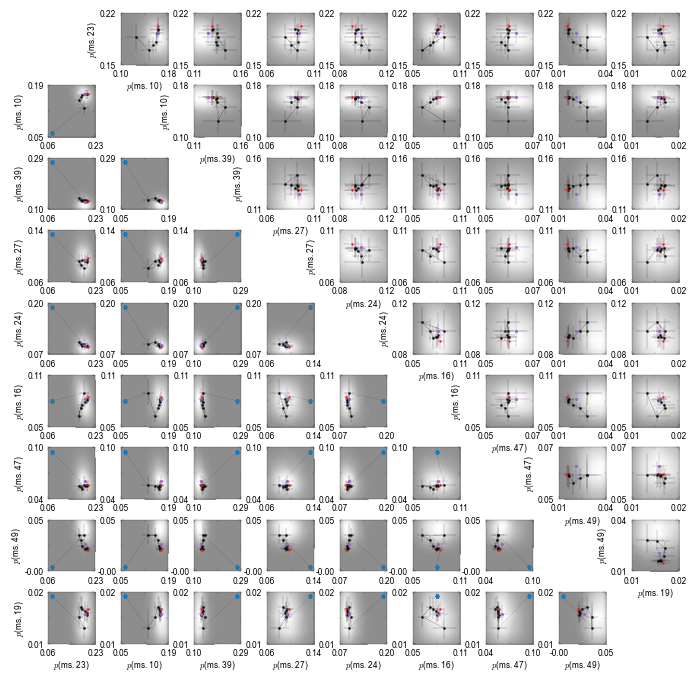

In [16]:
mpl.rcParams["xtick.labelsize"] = 6
mpl.rcParams["ytick.labelsize"] = 6


def format_s15_axes(ax):
    # Apply the shared axis formatting with S15-specific tick dimensions.
    stroke_in = 0.002
    lw = stroke_in * 72
    format_axes(ax, stroke_in=stroke_in)
    ax.tick_params(which='major', width=lw, length=2.5, direction='in',
                   top=True, bottom=True, left=True, right=True)
    ax.tick_params(which='minor', width=lw * 0.75, length=1.25, direction='in',
                   top=True, bottom=True, left=True, right=True)
    return ax


# Set up the figure
fig = plt.figure(figsize=(17.8/2.54, 17.8/2.54))

p_mean = p_med.copy()
s_mean = np.mean(s_vals)

# Create subplot layout (1 row, 3 columns)
gs = gridspec.GridSpec(n_plot_states, n_plot_states, figure=fig, wspace=0.55,hspace=0.4)

for i in range(n_plot_states):
    for j in range(i):
        ax = fig.add_subplot(gs[i, j])
        if i==n_plot_states-1:
            ax.set_xlabel('$p$(ms. '+str(plot_state_labels[j])+')',fontsize=6)
        if j==0:
            ax.set_ylabel('$p$(ms. '+str(plot_state_labels[i])+')',fontsize=6)

        
        ### Distribution of allowed points:
        x = distributions[:, j]
        y = distributions[:, i]
        xy = np.vstack([x, y])
        kde = gaussian_kde(xy)
        xx = np.linspace(0, 1, 200)
        yy = np.linspace(0, 1, 200)
        X, Y = np.meshgrid(xx, yy)
        Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
        # 1) Set axis background to same grey as the lowest density
        ax.set_facecolor("0.55")  # instead of the fill_between
        # 2) Define a colormap from medium grey to white
        grey_to_white = LinearSegmentedColormap.from_list(
            "grey_to_white",
            ["0.55", "1.0"]   # low density -> grey, high density -> white
        )
        # 3) Draw the full KDE field as filled contours
        levels_full = np.linspace(Z.min(), Z.max(), 80)
        cf = ax.contourf(X, Y, Z,
                          levels=levels_full,
                          cmap=grey_to_white,linewidths=None)
        # Set the edge color for each collection of polygons
        for c in cf.collections:
            c.set_edgecolor("face") # This forces the edge color to match the filled face color

        ax.plot([cold_eqm[j],dist_array[:,j][-1]],[cold_eqm[i],dist_array[:,i][-1]],color='black',ls=':',marker='none',alpha=0.7,lw=0.2,zorder=9)
        ax.plot([eqm_data[j],dist_array[:,j][0]],[eqm_data[i],dist_array[:,i][0]],color='black',ls=':',marker='none',alpha=0.7,lw=0.2,zorder=9)
        
        ax.errorbar(eqm_data[j],eqm_data[i],xerr=[[np.abs(eqm_data[j] - hot_eqm_low[j])],[np.abs(hot_eqm_high[j] - eqm_data[j])]],yerr=[[np.abs(eqm_data[i] - hot_eqm_low[i])],[np.abs(hot_eqm_high[i] - eqm_data[i])]],elinewidth=0.2,marker='*',color='tab:red',markersize=1,ls='none',lw=0.2,alpha=1,label='Hot Equilibrium',zorder=12)
        ax.errorbar(dist_array[:,j],dist_array[:,i],xerr=[np.abs(dist_array[:,j] - dist_low_array[:,j]),np.abs(dist_high_array[:,j] - dist_array[:,j])],yerr=[np.abs(dist_array[:,i] - dist_low_array[:,i]),np.abs(dist_high_array[:,i] - dist_array[:,i])],marker='o',color='black',markersize=1,ls='-',lw=0.2,elinewidth=0.2,alpha=0.7,label='Cooled Distributions',zorder=11)
        
        ax.scatter(cold_eqm[j],cold_eqm[i],marker=snowflake_path,color='tab:blue',s=10,zorder=12,label='Cold Equilibrium',alpha=1)
        ax.errorbar(p_mean[j],p_mean[i],xerr=[[p_err_low[j]],[p_err_high[j]]],yerr=[[p_err_low[i]],[p_err_high[i]]],marker='s',markersize=1,color='tab:purple',alpha=1,elinewidth=0.2,zorder=13,label='Inferred Distribution',lw=0)

        xmin = np.min([eqm_data[j],hot_eqm_low[j],p_mean[j]-p_err_low[j],cold_eqm[j],np.min(dist_array[:,j]),np.min(dist_low_array[:,j])])
        xmax = np.max([eqm_data[j],hot_eqm_high[j],p_mean[j]+p_err_high[j],cold_eqm[j],np.max(dist_array[:,j]),np.max(dist_high_array[:,j])])
        ymin = np.min([eqm_data[i],hot_eqm_low[i],p_mean[i]-p_err_low[i],cold_eqm[i],np.min(dist_array[:,i]),np.min(dist_low_array[:,i])])
        ymax = np.max([eqm_data[i],hot_eqm_high[i],p_err_high[i]+p_mean[i],cold_eqm[i],np.max(dist_array[:,i]),np.max(dist_high_array[:,i])])
        
        ax.set_xlim(xmin-0.1*(xmax-xmin),xmax+0.1*(xmax-xmin))
        ax.set_ylim(ymin-0.1*(ymax-ymin),ymax+0.1*(ymax-ymin))
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))


        format_s15_axes(ax)
        ax.xaxis.labelpad = 1
        ax.yaxis.labelpad = 1

        ax.xaxis.set_major_locator(ticker.LinearLocator(2))
        ax.yaxis.set_major_locator(ticker.LinearLocator(2))
        ax.set_xticks(np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 2))
        ax.set_yticks(np.linspace(ax.get_ylim()[0], ax.get_ylim()[1], 2))
        
for j in range(n_plot_states):
    for i in range(j):
        ax = fig.add_subplot(gs[i, j])
        if j==i+1:
            ax.set_ylabel('$p$(ms. '+str(plot_state_labels[i])+')',fontsize=6)
            ax.set_xlabel('$p$(ms. '+str(plot_state_labels[j])+')',fontsize=6)


        ### Distribution of allowed points:
        x = distributions[:, j]
        y = distributions[:, i]
        xy = np.vstack([x, y])
        kde = gaussian_kde(xy)
        xx = np.linspace(0, 1, 200)
        yy = np.linspace(0, 1, 200)
        X, Y = np.meshgrid(xx, yy)
        Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
        # 1) Set axis background to same grey as the lowest density
        ax.set_facecolor("0.55")  # instead of the fill_between
        # 2) Define a colormap from medium grey to white
        grey_to_white = LinearSegmentedColormap.from_list(
            "grey_to_white",
            ["0.55", "1.0"]   # low density -> grey, high density -> white
        )
        # 3) Draw the full KDE field as filled contours
        levels_full = np.linspace(Z.min(), Z.max(), 80)
        cf = ax.contourf(X, Y, Z,
                          levels=levels_full,
                          cmap=grey_to_white,linewidths=None)
        # Set the edge color for each collection of polygons
        for c in cf.collections:
            c.set_edgecolor("face") # This forces the edge color to match the filled face color

        ax.plot([eqm_data[j],dist_array[:,j][0]],[eqm_data[i],dist_array[:,i][0]],color='black',ls=':',marker='none',alpha=0.7,lw=0.2,zorder=9)
        
        ax.errorbar(eqm_data[j],eqm_data[i],xerr=[[np.abs(eqm_data[j] - hot_eqm_low[j])],[np.abs(hot_eqm_high[j] - eqm_data[j])]],yerr=[[np.abs(eqm_data[i] - hot_eqm_low[i])],[np.abs(hot_eqm_high[i] - eqm_data[i])]],elinewidth=0.2,marker='*',color='tab:red',markersize=1,ls='none',lw=0.2,alpha=1,label='Hot Equilibrium',zorder=12)
        ax.errorbar(dist_array[:,j],dist_array[:,i],xerr=[np.abs(dist_array[:,j] - dist_low_array[:,j]),np.abs(dist_high_array[:,j] - dist_array[:,j])],yerr=[np.abs(dist_array[:,i] - dist_low_array[:,i]),np.abs(dist_high_array[:,i] - dist_array[:,i])],marker='o',color='black',markersize=1,ls='-',lw=0.2,elinewidth=0.2,alpha=0.7,label='Cooled Distributions',zorder=11)
        
        ax.errorbar(p_mean[j],p_mean[i],xerr=[[p_err_low[j]],[p_err_high[j]]],yerr=[[p_err_low[i]],[p_err_high[i]]],marker='s',markersize=1,color='tab:purple',alpha=1,elinewidth=0.2,zorder=13,label='Inferred Distribution',lw=0)

        xmin = np.min([eqm_data[j],hot_eqm_low[j],p_mean[j]-p_err_low[j],np.min(dist_array[:,j]),np.min(dist_low_array[:,j])])
        xmax = np.max([eqm_data[j],hot_eqm_high[j],p_err_high[j]+p_mean[j],np.max(dist_array[:,j]),np.max(dist_high_array[:,j])])
        ymin = np.min([eqm_data[i],hot_eqm_low[i],p_mean[i]-p_err_low[i],np.min(dist_array[:,i]),np.min(dist_low_array[:,i])])
        ymax = np.max([eqm_data[i],hot_eqm_high[i],p_err_high[i]+p_mean[i],np.max(dist_array[:,i]),np.max(dist_high_array[:,i])])
        
        ax.set_xlim(xmin-0.1*(xmax-xmin),xmax+0.1*(xmax-xmin))
        ax.set_ylim(ymin-0.1*(ymax-ymin),ymax+0.1*(ymax-ymin))
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))


        format_s15_axes(ax)
        ax.xaxis.labelpad = 1
        ax.yaxis.labelpad = 1
        
        #ax.tick_params(axis='both', labelsize=6)
        ax.xaxis.set_major_locator(ticker.LinearLocator(2))
        ax.yaxis.set_major_locator(ticker.LinearLocator(2))
        ax.set_xticks(np.linspace(ax.get_xlim()[0], ax.get_xlim()[1], 2))
        ax.set_yticks(np.linspace(ax.get_ylim()[0], ax.get_ylim()[1], 2))

plt.savefig('Figure_S15.pdf')
plt.tight_layout(pad=0)
plt.show()



